# Cuatro noches para contar mosquitos

Mateo Caballero Serna, Lucian Valle Aguilar

Este notebook tiene los puntos 2, 3 y 4 del reto. El punto 1 está en `../EstimacionFermi_00/` y el plan en `../PlanAnalisis_01/`.

Datos: Ahumada ML et al. (2023). *Especies del género Anopheles asociadas al domicilio humano en 25 localidades de Timbiquí, Guapi y Santa Bárbara*. v1.0. INS. doi:10.15472/kftrcn (CC BY-NC 4.0).

In [1]:
import os, re, zipfile, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import nbinom, spearmanr
from sklearn.ensemble import RandomForestRegressor
warnings.filterwarnings("ignore")

RUTA_ZIP = "data/dwca-ins_mosquiteros_malaria-v1.0.zip"
CORTE = pd.Timestamp("2022-11-01")
rng = np.random.default_rng(42)
os.makedirs("figuras", exist_ok=True)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

with zipfile.ZipFile(RUTA_ZIP) as z:
    with z.open("occurrence.txt") as f:
        crudo = pd.read_csv(f, sep="\t", dtype=str, keep_default_na=False)
print(crudo.shape)

(1502, 68)


# Punto 2: En la comunidad

## Nuestra hoja de campo y la del estudio

Nuestra hoja está en `../PlanAnalisis_01/hoja_de_campo.md`. Al compararla con los registros:

- **Lo que el estudio registró y no habíamos pensado:** que los dos colectores cambian de lugar cada hora (así un colector "más atractivo" no sesga la comparación adentro/afuera), y la fase del ensayo (línea base o intervención).
- **Lo que echamos de menos:** el archivo no trae sitio (adentro/afuera), hora, casa, noche, ceros, lluvia ni qué intervención recibió cada lugar. El estudio sí anotó sitio, casa y hora en campo, pero publicó los datos sumados.

## ¿Cómo se produjeron los datos y qué tan confiables son?

Según los metadatos: en cada casa elegida al azar hay dos colectores, uno adentro y otro afuera, que capturan con aspirador lo que se les posa en la pierna, de 5:00 pm a 5:00 am (en la línea base, hasta las 7:00 am), y cambian de lugar cada hora. Es un ensayo por conglomerados que evalúa mosquiteros con insecticida y rociado de las casas, con capturas mensuales. Los mosquitos se identificaron en laboratorio con claves.

Cada fila es el total de **una especie** en **un evento** (un conglomerado en una campaña mensual, por ejemplo `Chete1-05`), sumando todas las casas, noches y horas. El esfuerzo viene como texto ("12 h por noche, 4 noches").

In [2]:
ev0 = crudo.drop_duplicates("eventID").copy()
ini = pd.to_datetime(ev0.eventDate.str.split("/").str[0], errors="coerce")
fin = pd.to_datetime(ev0.eventDate.str.split("/").str[-1], errors="coerce")
horas0 = ev0.samplingEffort.str.extract(r"(\d+) h")[0].astype(int)
noches0 = ev0.samplingEffort.str.extract(r"(\d+) noche")[0].astype(int)

print("Eventos:", len(ev0), "| especies:", crudo.scientificName.value_counts().to_dict())
print("Mosquitos:", crudo.individualCount.astype(int).sum(), "| noches en el archivo:", noches0.sum(), "(el resumen del EML dice 285)")
print("Todos los registros son 'present' (no hay ceros):", (crudo.occurrenceStatus == "present").all())
print("Duplicados exactos:", crudo.drop(columns=["id", "occurrenceID"]).duplicated().sum(),
      "| especie repetida en un evento:", crudo.duplicated(["eventID", "scientificName"]).sum())
print("Eventos sin fecha:", ini.isna().sum())
print("Eventos con '7 h por noche' pero horario de 14 h:", ((horas0 == 7) & (ev0.eventTime == "17:00:00/07:00:00")).sum())
print("Eventos donde el rango de fechas es más corto que las noches:", ((fin - ini).dt.days + 1 < noches0).sum())
print("Subgéneros por especie:\n", pd.crosstab(crudo.scientificName, crudo.subgenus))
print("Filas con coordenadas que no coinciden con el municipio:", (crudo.georeferenceRemarks != "").sum())
print("Códigos de conglomerado distintos en la línea base:", sorted(p for p in crudo.parentEventID.unique() if "_" in p))

Eventos: 879 | especies: {'Anopheles neivai': 823, 'Anopheles albimanus': 504, 'Anopheles apicimacula': 175}
Mosquitos: 229394 | noches en el archivo: 2900 (el resumen del EML dice 285)
Todos los registros son 'present' (no hay ceros): True
Duplicados exactos: 2 | especie repetida en un evento: 7
Eventos sin fecha: 13
Eventos con '7 h por noche' pero horario de 14 h: 4
Eventos donde el rango de fechas es más corto que las noches: 6
Subgéneros por especie:
 subgenus               Anopheles  Kerteszia  Nyssorhynchus
scientificName                                            
Anopheles albimanus            0          0            504
Anopheles apicimacula        175          0              0
Anopheles neivai               7        816              0
Filas con coordenadas que no coinciden con el municipio: 92
Códigos de conglomerado distintos en la línea base: ['BrazoC_01', 'BrazoC_02', 'Charco_01', 'Charco_02', 'Coteje1_01', 'Coteje1_02', 'Esperanza_01', 'Esperanza_02', 'Mataco_01', 'Matac

Encontramos: filas duplicadas, años mal escritos (campañas de 2023 registradas como 2022), eventos sin fecha, esfuerzo que no coincide con el horario en Temuey, *An. neivai* en el subgénero equivocado, códigos de conglomerado distintos en las dos primeras campañas, coordenadas que no coinciden con el municipio, y 2 900 noches en el archivo frente a 285 en el resumen. Como las noches no son consecutivas (el rango de fechas es más largo que las noches), no sabemos en qué noche se capturó cada mosquito.

Nada de esto invalida los datos, pero hay que tratarlo antes de calcular.

## Limpieza

- Duplicados exactos: se quita la copia. Especie repetida en un evento: se suman los conteos.
- Códigos de la línea base (`BrazoC_01`): se unifican con el resto (`BrazoC`, campaña 1).
- Año mal escrito: si la fecha queda a más de 180 días de la fecha típica de su campaña, se corrige el año. Eventos sin fecha: reciben la fecha típica de su campaña.
- "7 h por noche" con horario de 14 h: se usan 14 h.
- Especie que no aparece en un evento: cuenta como 0. Evento que no aparece: dato faltante, no cero.
- Esfuerzo = horas × noches × 2 colectores. Suponemos que cada noche es una casa con dos colectores. Tasa = mosquitos / persona-hora.

In [3]:
def conglomerado_y_campana(eid):
    m = re.match(r"^(.*)-(\d+)$", eid)
    if m:
        return m.group(1).replace("_", ""), int(m.group(2))
    m = re.match(r"^(.*)_0?(\d+)$", eid)
    return m.group(1), int(m.group(2))


def limpiar(df):
    d = df.drop_duplicates(subset=[c for c in df.columns if c not in ("id", "occurrenceID")]).copy()
    d["n"] = d.individualCount.astype(int)
    cc = d.eventID.map(conglomerado_y_campana)
    d["conglomerado"], d["campana"] = cc.str[0], cc.str[1]
    d["inicio"] = pd.to_datetime(d.eventDate.str.split("/").str[0], errors="coerce")
    d["horas"] = d.samplingEffort.str.extract(r"(\d+) h")[0].astype(int).replace(7, 14)
    d["noches"] = d.samplingEffort.str.extract(r"(\d+) noche")[0].astype(int)
    d["especie"] = d.scientificName.str.replace("Anopheles ", "An. ")
    d["lon"] = pd.to_numeric(d.decimalLongitude, errors="coerce")
    return d


def corregir_fechas(info):
    info = info.copy()
    esperado = info.campana.map(info.groupby("campana").inicio.median())
    info["corregida"] = False
    for i in info.index[(info.inicio - esperado).abs() > pd.Timedelta(days=180)]:
        v = info.at[i, "inicio"]
        nueva = min([v.replace(year=v.year - 1), v.replace(year=v.year + 1)], key=lambda z: abs(z - esperado[i]))
        if abs(nueva - esperado[i]) < pd.Timedelta(days=90):
            info.at[i, "inicio"], info.at[i, "corregida"] = nueva, True
    info["imputada"] = info.inicio.isna()
    info.loc[info.imputada, "inicio"] = esperado[info.imputada]
    return info


def tabla_eventos(d):
    info = d.groupby(["eventID", "conglomerado", "campana"], as_index=False).agg(
        inicio=("inicio", "min"), horas=("horas", "first"), noches=("noches", "first"))
    mun = d.groupby("conglomerado").county.agg(lambda x: x.mode()[0])
    mun[["Bellavista", "ElFirme", "LasPeñas", "Micaelita"]] = "Santa Bárbara"
    info["municipio"] = info.conglomerado.map(mun)
    info = corregir_fechas(info)
    sp = d.pivot_table(index="eventID", columns="especie", values="n", aggfunc="sum", fill_value=0)
    ev = info.merge(sp, left_on="eventID", right_index=True)
    ev["total"] = ev[list(sp.columns)].sum(axis=1)
    ev["persona_h"] = ev.horas * ev.noches * 2
    ev["tasa"] = ev.total / ev.persona_h
    return ev.sort_values(["inicio", "conglomerado"]).reset_index(drop=True), list(sp.columns)


datos = limpiar(crudo)
eventos, ESPECIES = tabla_eventos(datos)
lon = datos.groupby("conglomerado").lon.median()
print(f"{len(eventos)} eventos, {eventos.conglomerado.nunique()} conglomerados, {eventos.campana.max()} campañas")
print("Fechas corregidas:", eventos.corregida.sum(), "| imputadas:", eventos.imputada.sum())

879 eventos, 40 conglomerados, 23 campañas
Fechas corregidas: 7 | imputadas: 12


## Campañas reservadas

Reservamos todos los eventos que empiezan desde el **1 de noviembre de 2022** (las últimas campañas). La regla se fijó solo con las fechas y el número de eventos por mes, y se aplica después de corregir los años. Estos eventos no se usan hasta la evaluación final del punto 3.

In [4]:
reservado = eventos[eventos.inicio >= CORTE]
entreno = eventos[eventos.inicio < CORTE].copy()
reservado[["eventID", "conglomerado", "campana", "inicio"]].to_csv("campanas_reservadas.csv", index=False)
print(f"Reservados: {len(reservado)} ({len(reservado) / len(eventos):.0%}), de Cheté: {reservado.conglomerado.str.startswith('Chete').sum()}")
print(f"Entrenamiento: {len(entreno)} eventos")
chete = entreno[entreno.conglomerado.str.startswith("Chete")]

Reservados: 200 (23%), de Cheté: 10
Entrenamiento: 679 eventos


## Exploración

Como las visitas a un mismo lugar no son independientes, el bootstrap remuestrea conglomerados (para la zona) o campañas (para Cheté), no filas.

### ¿Cuántos *Anopheles* se capturan por persona-hora?

In [5]:
def tasa(df):
    return df.total.sum() / df.persona_h.sum()


def bootstrap(df, col, B=5000):
    grupos = [g for _, g in df.groupby(col)]
    res = [tasa(pd.concat([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])) for _ in range(B)]
    return np.percentile(res, [2.5, 97.5])


resumen = {}
for nombre, df, col in [("Toda la zona", entreno, "conglomerado"),
                        ("Timbiquí", entreno[entreno.municipio == "Timbiquí"], "conglomerado"),
                        ("Cheté", chete, "campana")]:
    lo, hi = bootstrap(df, col)
    resumen[nombre] = (tasa(df), lo, hi)
    print(f"{nombre:<13} {tasa(df):.2f}  IC95 [{lo:.2f}, {hi:.2f}]  (mediana por evento {df.tasa.median():.2f})")
print("Cheté por conglomerado (mediana):", chete.groupby("conglomerado").tasa.median().round(2).to_dict())
print("Rango de la tasa entre eventos:", entreno.tasa.min().round(2), "a", entreno.tasa.max().round(2))

Toda la zona  3.33  IC95 [2.69, 4.00]  (mediana por evento 2.12)


Timbiquí      3.93  IC95 [2.93, 4.96]  (mediana por evento 2.96)
Cheté         2.14  IC95 [1.73, 2.53]  (mediana por evento 1.60)
Cheté por conglomerado (mediana): {'Chete1': 3.0, 'Chete2': 0.81}
Rango de la tasa entre eventos: 0.01 a 20.74


La tasa cambia muchísimo de un evento a otro. Cheté captura menos que la zona y que el resto de Timbiquí, y sus dos conglomerados son muy distintos: Chete1 captura varias veces más que Chete2.

### ¿Qué especies se capturan y dónde?

municipio        Guapi  Santa Bárbara  Timbiquí
An. albimanus    0.049          0.204     0.231
An. apicimacula  0.004          0.005     0.001
An. neivai       0.947          0.791     0.768

Cheté: {'An. albimanus': 0.986, 'An. apicimacula': 0.001, 'An. neivai': 0.013}


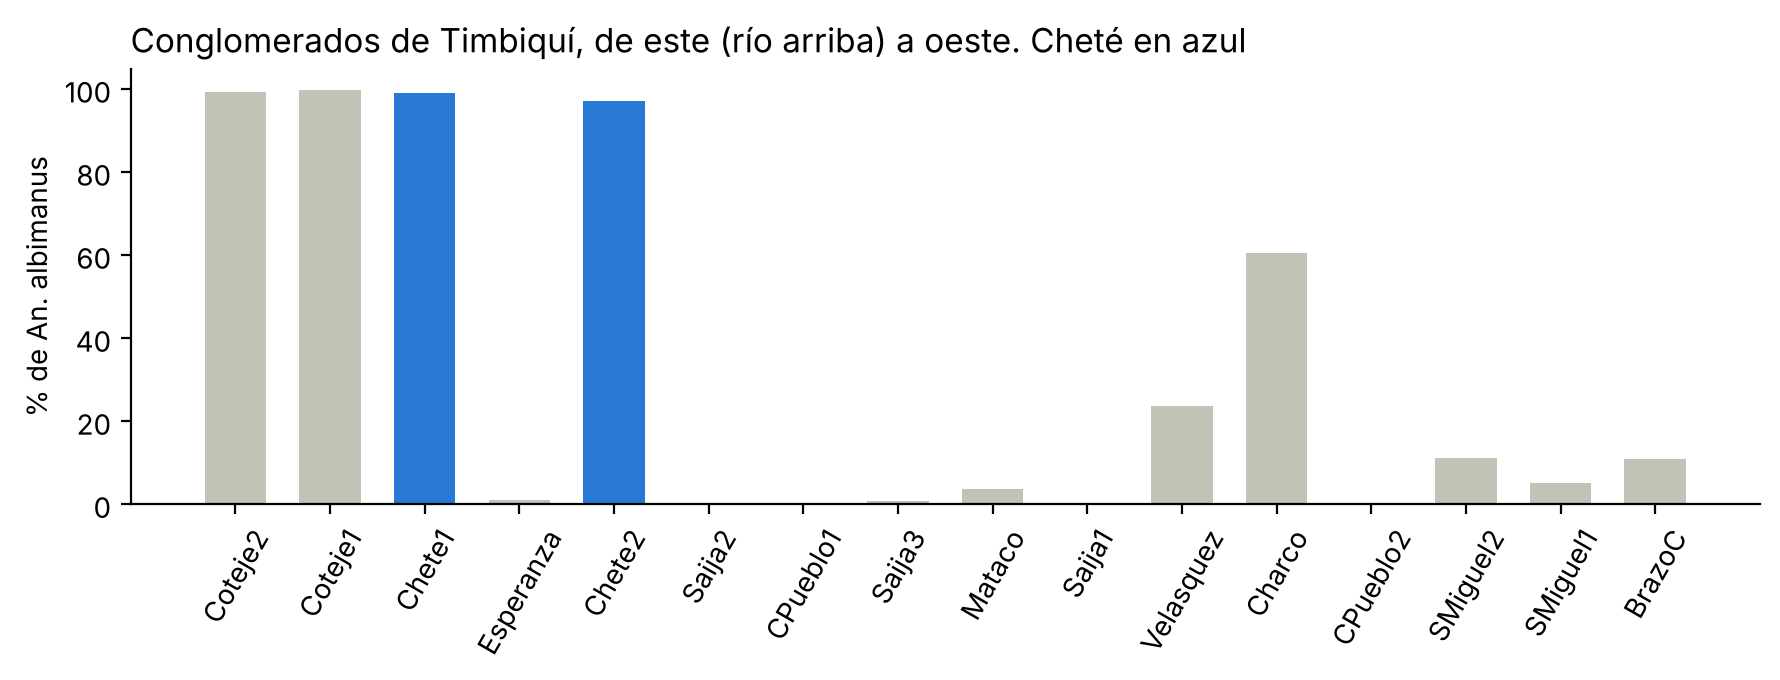

In [6]:
print((entreno.groupby("municipio")[ESPECIES].sum().T / entreno.groupby("municipio").total.sum()).round(3))
print("\nCheté:", (chete[ESPECIES].sum() / chete.total.sum()).round(3).to_dict())

pc = entreno.groupby(["municipio", "conglomerado"])[["An. albimanus", "total"]].sum()
pc["p_alb"] = pc["An. albimanus"] / pc.total
t = pc.loc["Timbiquí"].join(lon).sort_values("lon", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(t.index, 100 * t.p_alb, color=[AZUL if c.startswith("Chete") else GRIS for c in t.index], width=0.65)
ax.set_ylabel("% de An. albimanus")
ax.set_title("Conglomerados de Timbiquí, de este (río arriba) a oeste. Cheté en azul", loc="left")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("figuras/albimanus_timbiqui.png", dpi=200, bbox_inches="tight"); plt.show()

En la zona domina *An. neivai*, que se cría en el agua de las bromelias del bosque. En Cheté casi todo es *An. albimanus*, que se cría en charcos y aguas abiertas, y que es el vector principal según el proyecto. Coteje, el vecino de Cheté, se comporta igual.

### ¿Cambia la tasa con el tiempo?

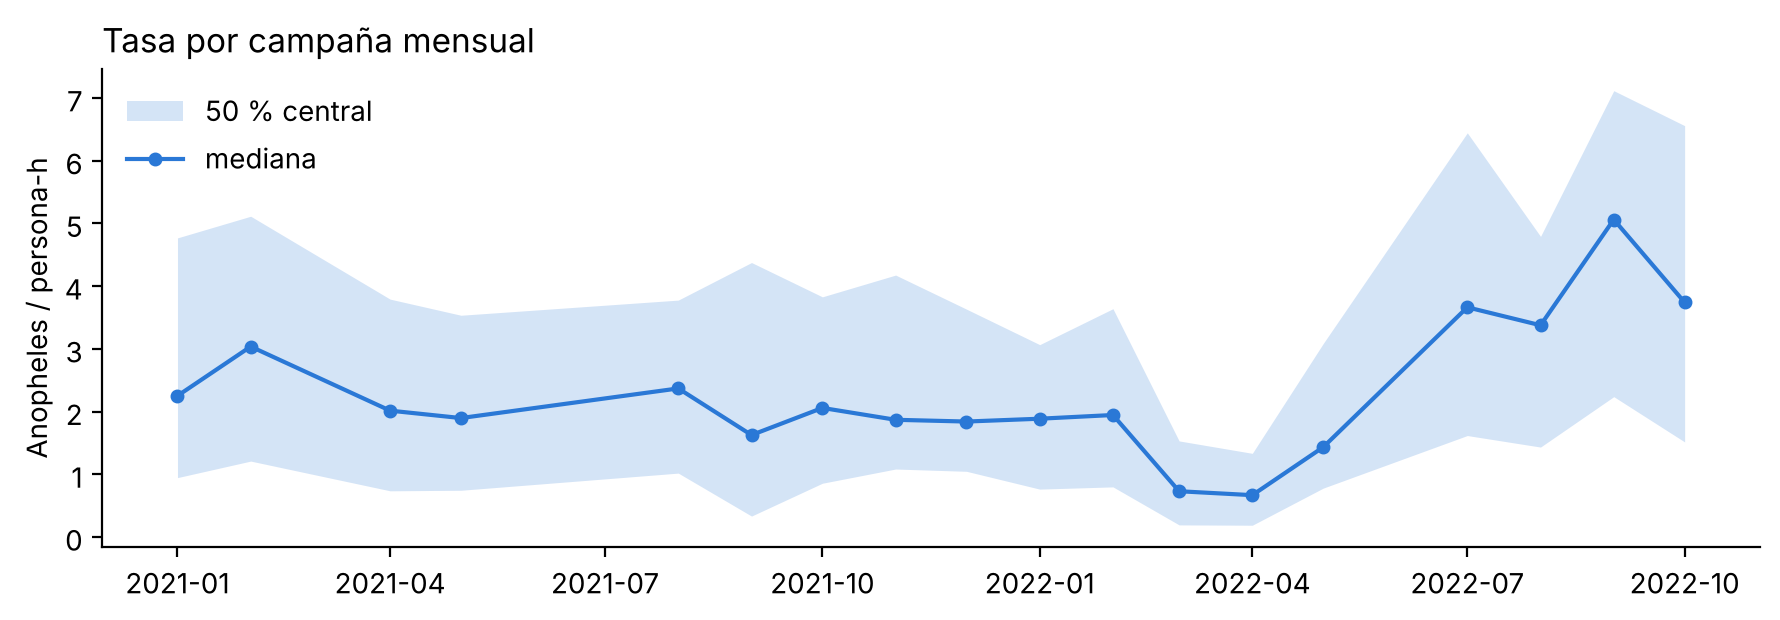

Línea base (ene-feb 2021): mediana 2.32 | después: 2.10


In [7]:
mensual = entreno.groupby(entreno.inicio.dt.to_period("M")).tasa.describe()[["count", "25%", "50%", "75%"]]
x = mensual.index.to_timestamp()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.fill_between(x, mensual["25%"], mensual["75%"], color=AZUL, alpha=0.2, lw=0, label="50 % central")
ax.plot(x, mensual["50%"], color=AZUL, marker="o", ms=4, label="mediana")
ax.set_ylabel("Anopheles / persona-h")
ax.set_title("Tasa por campaña mensual", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/tasa_mensual.png", dpi=200, bbox_inches="tight"); plt.show()

base, resto = entreno[entreno.horas == 14], entreno[entreno.horas != 14]
print(f"Línea base (ene-feb 2021): mediana {base.tasa.median():.2f} | después: {resto.tasa.median():.2f}")

La tasa baja en marzo y abril de 2022 y sube en la segunda mitad de 2022. Faltan meses enteros y cada mes aparece una o dos veces, así que no se puede separar la estacionalidad de las fases del ensayo. Antes y después de la línea base la mediana es parecida, pero eso no dice nada de las intervenciones: la línea base solo cubre enero y febrero, y no sabemos qué recibió cada conglomerado.

## Volviendo a la estimación de Fermi

En el punto 1 estimamos 442 *Anopheles* (rango 61 a 3 014) para 288 persona-horas. Multiplicamos la tasa real por las mismas 288 persona-horas:

In [8]:
for nombre, (r, lo, hi) in resumen.items():
    print(f"{nombre:<13} {288 * r:5.0f}  IC95 [{288 * lo:.0f}, {288 * hi:.0f}]  = {288 * r / 442:.1f} veces nuestra mediana")

Toda la zona    958  IC95 [773, 1152]  = 2.2 veces nuestra mediana
Timbiquí       1133  IC95 [843, 1429]  = 2.6 veces nuestra mediana
Cheté           616  IC95 [499, 728]  = 1.4 veces nuestra mediana


- **Resistió:** el resultado. Cheté da más que nuestra mediana pero queda dentro de nuestro rango. También el diseño: el estudio usa justo un colector adentro y otro afuera durante 12 horas.
- **Resistió a medias:** $m_{crianza}$. Pensamos en charcos y río, y eso encaja con *An. albimanus* en Cheté, pero no pensamos en las bromelias, que es donde se cría *An. neivai*, la especie más común de la zona.
- **Cayó:** suponer casas y noches iguales. Los dos conglomerados de Cheté son muy distintos y la tasa cambia mucho de un mes a otro.
- **No se puede comprobar:** $k_{intra}$ (no hay sitio) ni $f_{Anoph}$ (solo se registró *Anopheles*). Como esperábamos, solo se puede comprobar la tasa completa, no cada factor.

## Hallazgo puesto a prueba

**Hallazgo:** en Cheté casi todo lo capturado es *An. albimanus*, al contrario de la mayor parte de la zona. Lo probamos con otras decisiones razonables: cada conglomerado por separado, cada año, la proporción por evento en vez del total, otra limpieza (sin sumar repetidos y sin fechas corregidas), y una permutación exacta entre los 16 conglomerados de Timbiquí, permutando conglomerados y no eventos.

In [9]:
def p_alb(df):
    return df["An. albimanus"].sum() / df.total.sum()


print("Por conglomerado:", chete.groupby("conglomerado").apply(p_alb).round(3).to_dict())
print("Por año:", chete.groupby(chete.inicio.dt.year).apply(p_alb).round(3).to_dict())
print("Mediana por evento:", round((chete["An. albimanus"] / chete.total).median(), 3))

ev_alt, _ = tabla_eventos(limpiar(crudo.drop_duplicates(["eventID", "scientificName"])))
ev_alt = ev_alt[(ev_alt.inicio < CORTE) & ~ev_alt.corregida & ~ev_alt.imputada]
print("Otra limpieza: Cheté", round(p_alb(ev_alt[ev_alt.conglomerado.str.startswith("Chete")]), 3), "| zona", round(p_alb(ev_alt), 3))

pt = pc.loc["Timbiquí"].p_alb
obs = pt[["Chete1", "Chete2"]].mean()
parejas = list(combinations(pt.index, 2))
extremas = [p for p in parejas if pt[list(p)].mean() >= obs - 1e-12]
print(f"\nPermutación: p = {len(extremas) / len(parejas):.3f} ({len(extremas)} de {len(parejas)} parejas)", extremas)

tt = pt.to_frame().join(lon)
rho = spearmanr(tt.lon, tt.p_alb)[0]
perm = [spearmanr(tt.lon, rng.permutation(tt.p_alb.values))[0] for _ in range(10000)]
print(f"¿Gradiente a lo largo del río? rho = {rho:.2f}, p = {np.mean(np.abs(perm) >= abs(rho)):.3f}")

Por conglomerado: {'Chete1': 0.99, 'Chete2': 0.971}
Por año: {2021: 0.994, 2022: 0.98}
Mediana por evento: 0.995
Otra limpieza: Cheté 0.986 | zona 0.159

Permutación: p = 0.050 (6 de 120 parejas) [('Chete1', 'Chete2'), ('Chete1', 'Coteje1'), ('Chete1', 'Coteje2'), ('Chete2', 'Coteje1'), ('Chete2', 'Coteje2'), ('Coteje1', 'Coteje2')]


¿Gradiente a lo largo del río? rho = 0.39, p = 0.132


El hallazgo sigue en pie con todas las decisiones: Cheté da más del 95 % de *An. albimanus* en todos los casos. Pero la permutación muestra que Cheté no es único: las únicas parejas tan extremas son las que mezclan Cheté con Coteje (p = 0.05). Por eso lo reformulamos: **Cheté y Coteje, los conglomerados más al este, forman un grupo dominado por *An. albimanus***. La idea de un gradiente a lo largo de todo el río no se sostiene (p ≈ 0.13). No sabemos por qué pasa; puede ser el tipo de criaderos o algo que no está en los datos.

# Punto 3: Antes de la próxima visita

**Qué predecimos:** la tasa de captura (*Anopheles* por persona-hora) de cada evento. Con ella damos el total de una campaña de 4 noches en Cheté con nuestro diseño (288 persona-horas) y la probabilidad de pasar umbrales que cambian cuántos frascos llevar.

**Cuándo es buena una predicción:** cuando se equivoca menos que una referencia sencilla y sus intervalos del 80 % contienen lo real más o menos el 80 % de las veces. Medimos el error en escala log (MAE de $\log_{10}$ de la tasa), porque los conteos van de unos pocos a miles: equivocarse por el doble importa igual en ambos casos. Un MAE de 0.3 significa equivocarse por un factor de $10^{0.3} \approx 2$.

**Solo información previa a cada campaña:** el modelo usa la historia del conglomerado (promedio de sus campañas anteriores y la última), la tasa de la zona el mes anterior, el mes del año y el municipio.

In [10]:
ev = eventos.copy()
ev["ltasa"] = np.log(ev.tasa)
ev["mes_obs"] = ev.inicio.dt.to_period("M")
g = ev.groupby("conglomerado").ltasa
ev["ultima"] = g.shift(1)
ev["historica"] = g.transform(lambda s: s.shift(1).expanding().mean())
ev["zona_mes_ant"] = ev.mes_obs.map(ev.groupby("mes_obs").ltasa.median().shift(1)).fillna(ev.ltasa.iloc[:40].mean())
ev["ultima"] = ev.ultima.fillna(ev.zona_mes_ant)
ev["historica"] = ev.historica.fillna(ev.zona_mes_ant)
ev["mes_sin"] = np.sin(2 * np.pi * ev.inicio.dt.month / 12)
ev["mes_cos"] = np.cos(2 * np.pi * ev.inicio.dt.month / 12)
ev["timbiqui"] = (ev.municipio == "Timbiquí").astype(int)
ev["sbarbara"] = (ev.municipio == "Santa Bárbara").astype(int)
X = ["historica", "ultima", "zona_mes_ant", "mes_sin", "mes_cos", "timbiqui", "sbarbara"]

entreno = ev[ev.inicio < CORTE].copy()
reservado = ev[ev.inicio >= CORTE].copy()
print(f"Varianza / media de los totales: {entreno.total.var() / entreno.total.mean():.0f}  (sería 1 si fueran Poisson)")

Varianza / media de los totales: 320  (sería 1 si fueran Poisson)


Los conteos están muy sobredispersos, así que usamos una **regresión binomial negativa** con el log del esfuerzo como *offset*. La comparamos con un random forest y con cuatro referencias:

- Fermi original: la tasa de nuestra mediana del punto 1 (442 / 288 = 1.53).
- Fermi revisado: la tasa promedio de la zona (lo que diríamos después del punto 2).
- Persistencia: igual que la campaña anterior del conglomerado.
- Histórica: el promedio de las campañas anteriores del conglomerado.

In [11]:
def ajustar_nb(df):
    exog, off = sm.add_constant(df[X]), np.log(df.persona_h)
    m = sm.GLM(df.total, exog, family=sm.families.NegativeBinomial(alpha=1.0), offset=off).fit()
    mu = m.fittedvalues
    alpha = max(1e-3, np.mean(((df.total - mu) ** 2 - mu) / mu ** 2))
    return sm.GLM(df.total, exog, family=sm.families.NegativeBinomial(alpha=alpha), offset=off).fit(), alpha


def predicciones(train, test):
    out = {"Fermi original": (np.full(len(test), 442 / 288), None, None),
           "Fermi revisado": (np.full(len(test), tasa(train)), None, None),
           "Persistencia": (np.exp(test.ultima.values), None, None)}
    h = np.exp(test.historica.values)
    qlo, qhi = np.quantile(train.ltasa - train.historica, [0.1, 0.9])
    out["Histórica"] = (h, h * np.exp(qlo), h * np.exp(qhi))
    m, a = ajustar_nb(train)
    mu = m.predict(sm.add_constant(test[X], has_constant="add"), offset=np.log(test.persona_h)).values
    n, ph = 1 / a, test.persona_h.values
    out["Binomial negativa"] = (mu / ph, nbinom.ppf(0.1, n, n / (n + mu)) / ph, nbinom.ppf(0.9, n, n / (n + mu)) / ph)
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0).fit(train[X], train.ltasa)
    out["Random forest"] = (np.exp(rf.predict(test[X])), None, None)
    return out


def evaluar(train, test):
    y, filas = test.tasa.values, {}
    for k, (p, lo, hi) in predicciones(train, test).items():
        filas[k] = {"MAE_log10": np.mean(np.abs(np.log10(p) - np.log10(y))),
                    "MAE_tasa": np.mean(np.abs(p - y)),
                    "cobertura80": np.mean((y >= lo) & (y <= hi)) if lo is not None else np.nan}
    r = pd.DataFrame(filas).T.sort_values("MAE_log10")
    r["factor"] = 10 ** r.MAE_log10
    return r

## Validación con origen móvil

Dentro del entrenamiento, para cada mes desde enero de 2022 entrenamos con todo lo anterior y predecimos ese mes. Así se respeta el orden del tiempo, y como las variables vienen del pasado de cada conglomerado, no se usa información futura del mismo lugar.

In [12]:
meses = [m for m in sorted(entreno.mes_obs.unique()) if m >= pd.Period("2022-01", "M")]
val = pd.concat([evaluar(entreno[entreno.mes_obs < m], entreno[entreno.mes_obs == m]) for m in meses])
val = val.groupby(level=0).mean().sort_values("MAE_log10")
val["factor"] = 10 ** val.MAE_log10
print(val.round(3))

modelo, alpha = ajustar_nb(entreno)
print(f"\nBinomial negativa (alpha = {alpha:.2f}):")
print(pd.DataFrame({"coef": modelo.params, "p": modelo.pvalues}).round(3))

                   MAE_log10  MAE_tasa  cobertura80  factor
Binomial negativa      0.362     1.888        0.795   2.302
Random forest          0.370     1.944          NaN   2.342
Histórica              0.374     2.047        0.764   2.368
Persistencia           0.418     2.155          NaN   2.618
Fermi original         0.479     2.473          NaN   3.012
Fermi revisado         0.482     2.505          NaN   3.034

Binomial negativa (alpha = 0.83):
               coef      p
const         0.514  0.000
historica     0.533  0.000
ultima        0.080  0.067
zona_mes_ant  0.137  0.139
mes_sin      -0.223  0.000
mes_cos      -0.036  0.520
timbiqui      0.060  0.472
sbarbara      0.175  0.173


Todos los modelos que conocen el conglomerado le ganan claramente a las dos versiones del Fermi. La binomial negativa queda primera, pero por muy poco frente a la histórica, y su cobertura está cerca de 0.80. Lo que más pesa en el modelo es la historia del conglomerado; el mes también importa (`mes_sin`), y la campaña anterior, la zona y el municipio aportan poco.

Elegimos la binomial negativa, y la histórica es la referencia a superar.

## Evaluación final en las campañas reservadas

Primera y única vez que usamos estas campañas.

In [13]:
final = evaluar(entreno, reservado)
print(final.round(3))
chete_res = reservado[reservado.conglomerado.str.startswith("Chete")]
print(f"\nSolo Cheté ({len(chete_res)} eventos):")
print(evaluar(entreno, chete_res).round(3))

p = predicciones(entreno, reservado)
err = {k: np.abs(np.log10(p[k][0]) - np.log10(reservado.tasa.values)) for k in ["Binomial negativa", "Histórica"]}
dif = pd.Series(err["Binomial negativa"] - err["Histórica"], index=reservado.conglomerado.values)
grupos = [v.values for _, v in dif.groupby(level=0)]
boot = [np.concatenate([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))]).mean() for _ in range(5000)]
print(f"\nDiferencia de error (binomial negativa - histórica): {dif.mean():+.3f}, IC95 {np.percentile(boot, [2.5, 97.5]).round(3)}")

                   MAE_log10  MAE_tasa  cobertura80  factor
Histórica              0.259     1.463        0.910   1.814
Random forest          0.278     1.471          NaN   1.895
Binomial negativa      0.281     1.447        0.925   1.908
Persistencia           0.324     1.871          NaN   2.110
Fermi original         0.413     2.161          NaN   2.585
Fermi revisado         0.431     2.319          NaN   2.697

Solo Cheté (10 eventos):


                   MAE_log10  MAE_tasa  cobertura80  factor
Histórica              0.151     0.817          1.0   1.417
Random forest          0.153     0.847          NaN   1.422
Persistencia           0.208     1.235          NaN   1.613
Binomial negativa      0.266     1.062          1.0   1.846
Fermi original         0.320     1.279          NaN   2.089
Fermi revisado         0.464     2.114          NaN   2.913



Diferencia de error (binomial negativa - histórica): +0.022, IC95 [-0.012  0.057]


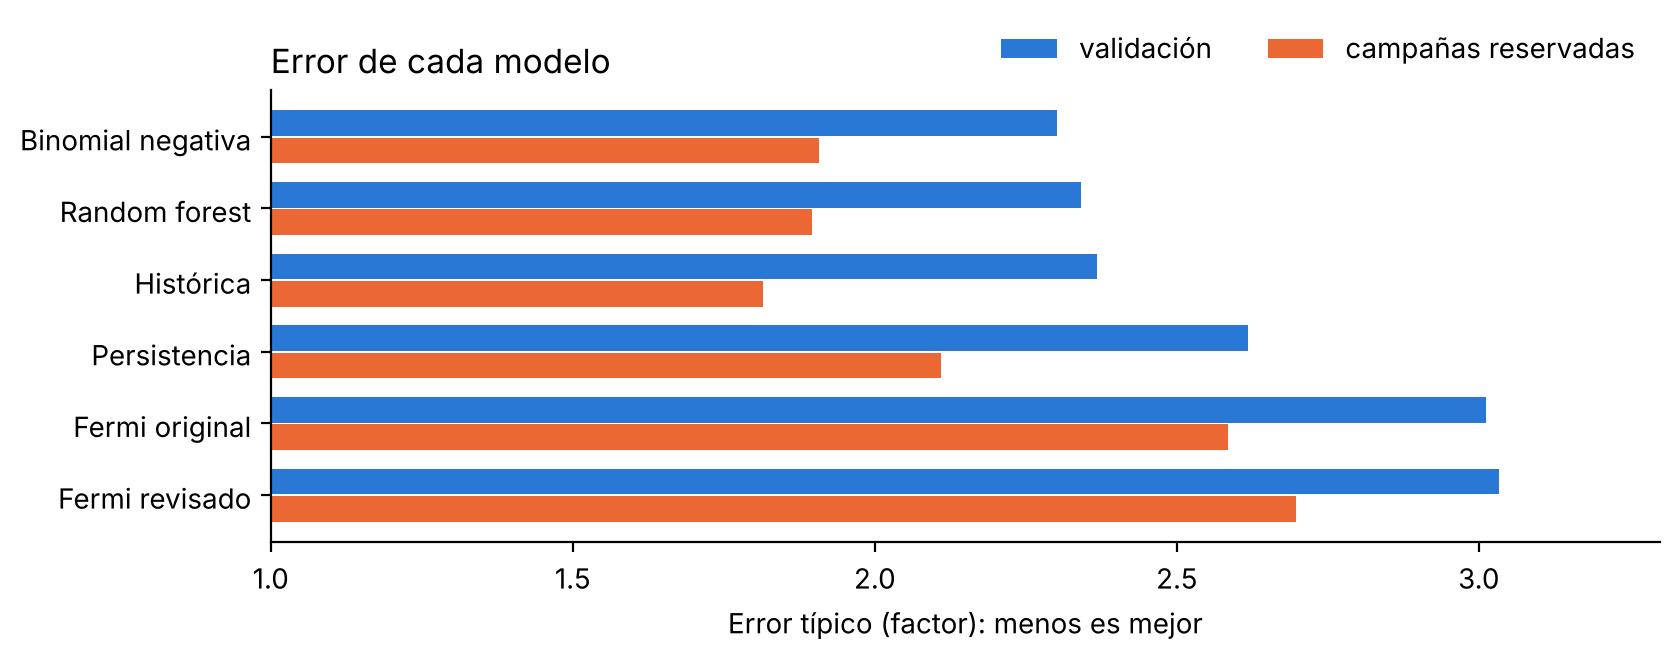

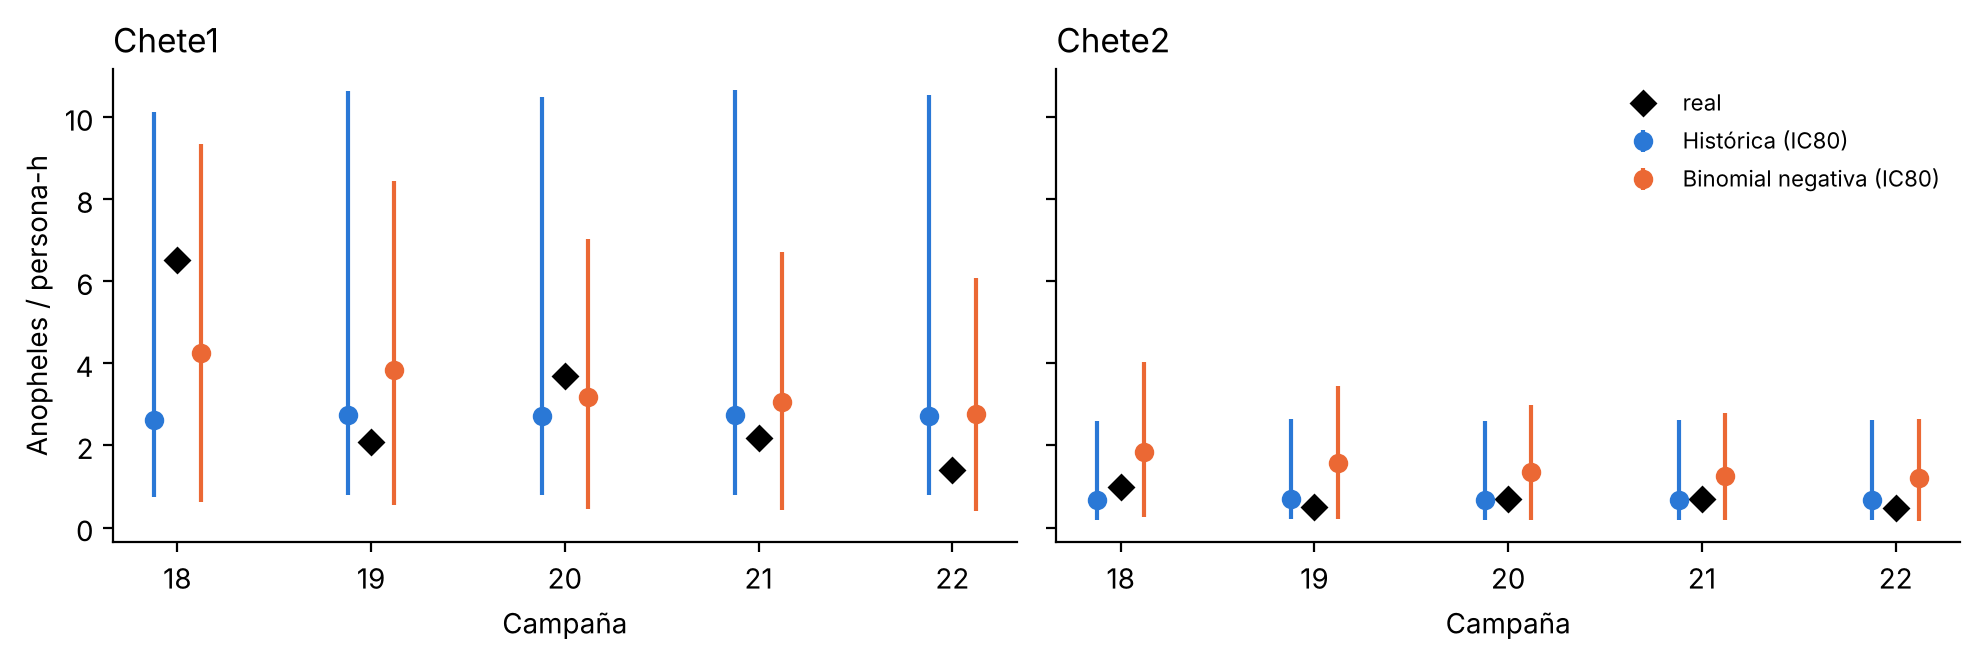

In [14]:
orden = val.index.tolist()
y = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(y - 0.19, val.loc[orden, "factor"], height=0.36, color=AZUL, label="validación")
ax.barh(y + 0.19, final.loc[orden, "factor"], height=0.36, color=NARANJA, label="campañas reservadas")
ax.set_yticks(y, orden)
ax.invert_yaxis()
ax.set_xlim(1, 3.3)
ax.set_xlabel("Error típico (factor): menos es mejor")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncol=2)
ax.set_title("Error de cada modelo", loc="left")
plt.tight_layout(); plt.savefig("figuras/error_modelos.png", dpi=200, bbox_inches="tight"); plt.show()

pc3 = predicciones(entreno, chete_res)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, cong in zip(axes, ["Chete1", "Chete2"]):
    i = np.where(chete_res.conglomerado.values == cong)[0]
    xc = chete_res.campana.values[i]
    for nombre, color, dx in [("Histórica", AZUL, -0.12), ("Binomial negativa", NARANJA, 0.12)]:
        pr, lo, hi = pc3[nombre]
        ax.errorbar(xc + dx, pr[i], yerr=[pr[i] - lo[i], hi[i] - pr[i]], fmt="o", color=color, label=f"{nombre} (IC80)")
    ax.plot(xc, chete_res.tasa.values[i], "D", color="black", label="real")
    ax.set_title(cong, loc="left")
    ax.set_xlabel("Campaña")
axes[0].set_ylabel("Anopheles / persona-h")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figuras/chete_predicho_vs_real.png", dpi=200, bbox_inches="tight"); plt.show()

En las campañas reservadas la binomial negativa **no le ganó a la histórica**: la histórica se equivocó un poco menos, y el intervalo de la diferencia incluye el 0. En Cheté la histórica es claramente mejor, porque la binomial negativa acerca a Chete2 al promedio de la zona y lo sobreestima. Los dos Fermi quedan de últimos. Los intervalos del 80 % contuvieron algo más del 80 %, así que son honestos, aunque un poco anchos.

## Predicción para la próxima visita

Usamos la regla que mejor funcionó, la tasa histórica de cada conglomerado, ahora con todos los datos. El diseño es el del punto 1: 288 persona-horas, mitad en Chete1 y mitad en Chete2. Para la incertidumbre, cada campaña pasada de Cheté da un escenario: al nivel actual le sumamos el error que tuvieron los dos conglomerados en esa campaña (así un mes malo es malo para los dos).

Tasa típica: {'Chete1': 2.64, 'Chete2': 0.67} | escenarios: 20
Anopheles en 4 noches: mediana 659, intervalo 80 % [299, 1196]
P(más de 250): 95%
P(más de 500): 65%
P(más de 1000): 20%
P(más de 1500): 10%
Frascos: 14 para la mediana, 24 para el p90
Especies en Cheté: {'An. albimanus': 0.982, 'An. apicimacula': 0.001, 'An. neivai': 0.017}


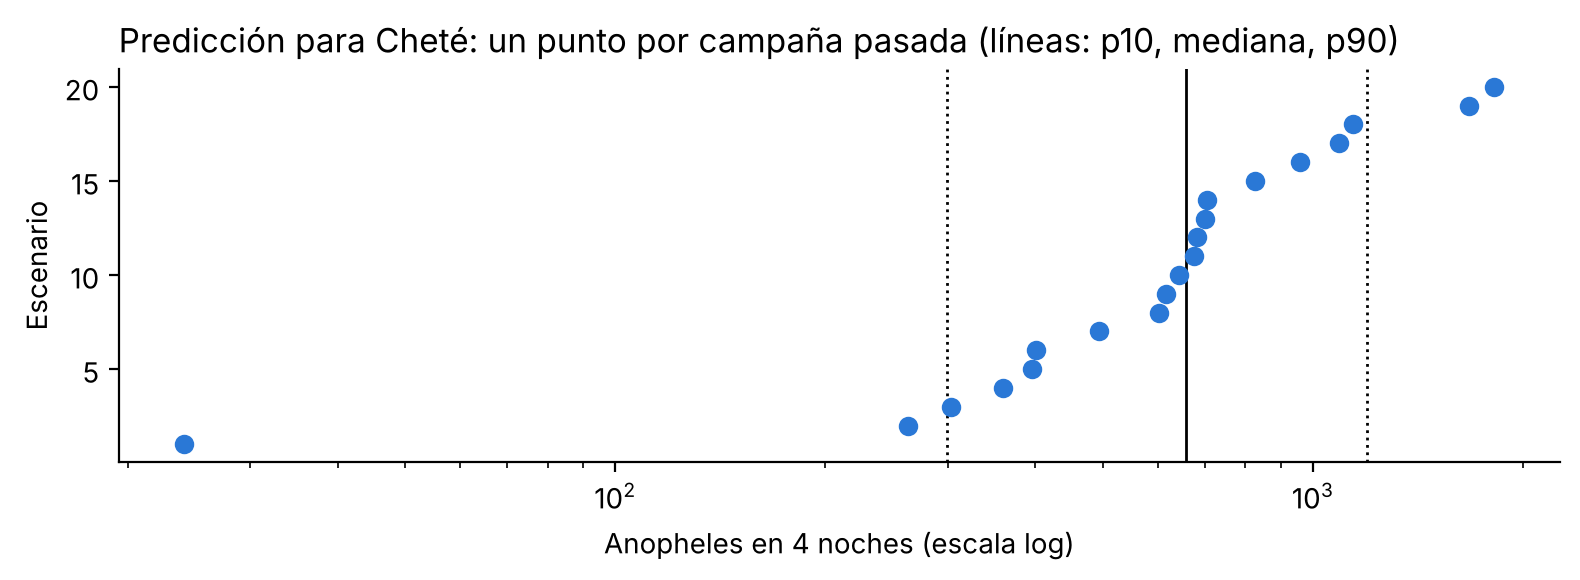

In [15]:
PERSONA_H = {"Chete1": 144, "Chete2": 144}
CAPACIDAD_FRASCO = 50

ch = ev[ev.conglomerado.str.startswith("Chete")].copy()
ch["error"] = ch.ltasa - ch.historica
nivel = ch.groupby("conglomerado").ltasa.mean()
errores = ch.pivot_table(index="campana", columns="conglomerado", values="error").dropna()
errores = errores[errores.index > 2]
total = sum(np.exp(nivel[c] + errores[c].values) * PERSONA_H[c] for c in PERSONA_H)

q = np.percentile(total, [10, 50, 90])
print("Tasa típica:", np.exp(nivel).round(2).to_dict(), "| escenarios:", len(total))
print(f"Anopheles en 4 noches: mediana {q[1]:.0f}, intervalo 80 % [{q[0]:.0f}, {q[2]:.0f}]")
for u in [250, 500, 1000, 1500]:
    print(f"P(más de {u}): {np.mean(total > u):.0%}")
print(f"Frascos: {np.ceil(q[1] / CAPACIDAD_FRASCO):.0f} para la mediana, {np.ceil(q[2] / CAPACIDAD_FRASCO):.0f} para el p90")
print("Especies en Cheté:", (ch[ESPECIES].sum() / ch.total.sum()).round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(np.sort(total), np.arange(1, len(total) + 1), color=AZUL, zorder=3)
ax.set_xscale("log")
for v, ls in zip(q, [":", "-", ":"]):
    ax.axvline(v, color="black", lw=1, ls=ls)
ax.set_xlabel("Anopheles en 4 noches (escala log)")
ax.set_ylabel("Escenario")
ax.set_title("Predicción para Cheté: un punto por campaña pasada (líneas: p10, mediana, p90)", loc="left")
plt.tight_layout(); plt.savefig("figuras/prediccion_chete.png", dpi=200, bbox_inches="tight"); plt.show()

## ¿Le sirve este modelo al equipo?

Sí, pero lo útil no es el modelo más complejo sino saber de qué lugar se trata. Al equipo le diríamos:

- Esperen **unos 660 *Anopheles*** en 4 noches, probablemente entre 300 y 1 200, con un 20 % de probabilidad de pasar de mil. Lleven frascos para el valor alto (unos 24, si caben 50 por frasco), no para la mediana.
- Casi todo será *An. albimanus*, el vector principal.
- Chete1 captura unas cuatro veces más que Chete2: si cambian cuántas casas ponen en cada uno, la predicción cambia.

Con franqueza: aun con la mejor regla nos equivocamos por un factor típico cercano a 2 en cada evento, porque la variación de mes a mes no la explicamos con lo que hay en los datos (probablemente depende de la lluvia). Además, la predicción supone que nada cambió desde 2023, aunque las intervenciones o el clima pudieron cambiar las poblaciones.

# Punto 4: Lo que nos preguntamos en campo

**Pregunta:** si el equipo solo puede visitar un lugar unas pocas veces, ¿cuántas campañas hacen falta para conocer su tasa de captura con confianza?

Nos surgió al ver lo mucho que cambia la tasa de un mes a otro: si una campaña sola puede salir muy alta o muy baja, una sola visita a Cheté diría poco. La respuesta le sirve al equipo para decidir cuántas veces volver.

**Cómo:** para cada uno de los 40 conglomerados tomamos $k$ campañas al azar, calculamos su tasa típica (promedio del log) y la comparamos con la de **las demás** campañas del mismo conglomerado. Repetimos muchas veces y vemos el error típico y el error en el peor 10 % de los casos.

          error típico  peor 10 %
campañas                         
1                 1.73       4.54
2                 1.53       3.07
3                 1.41       2.59
4                 1.37       2.32
6                 1.33       2.08
8                 1.30       1.97
10                1.30       1.95


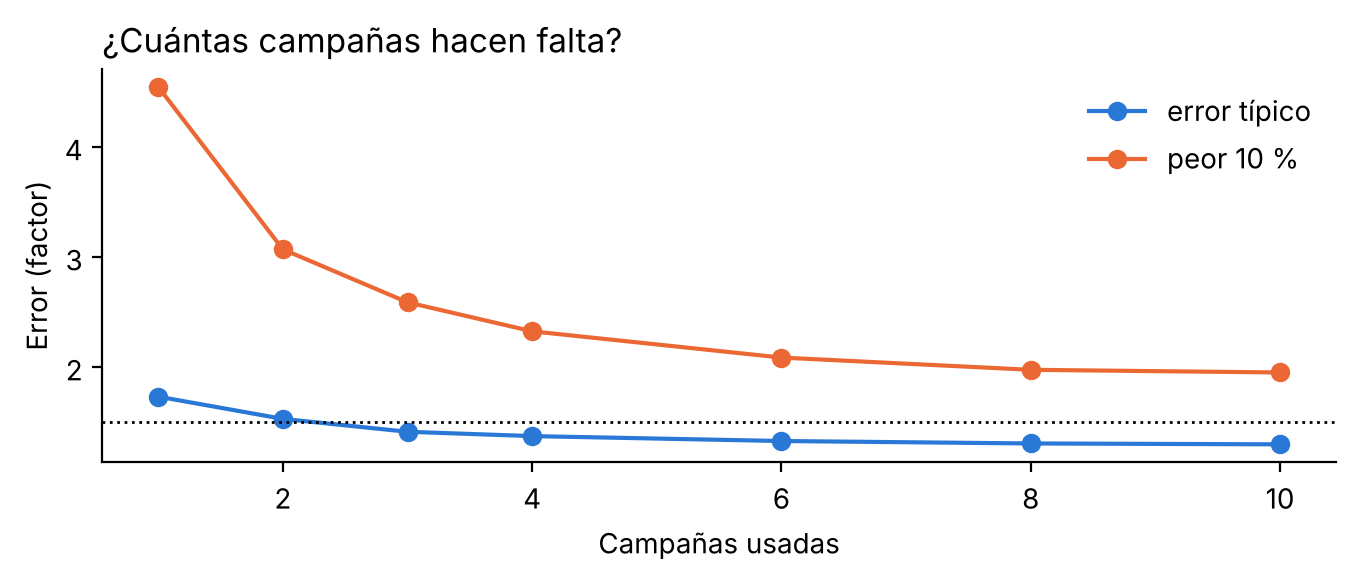

In [16]:
filas = []
for k in [1, 2, 3, 4, 6, 8, 10]:
    errs = []
    for _, gr in ev.groupby("conglomerado"):
        v = np.log10(gr.tasa.values)
        for _ in range(300):
            idx = rng.permutation(len(v))
            errs.append(abs(v[idx[:k]].mean() - v[idx[k:]].mean()))
    errs = 10 ** np.array(errs)
    filas.append({"campañas": k, "error típico": np.median(errs), "peor 10 %": np.percentile(errs, 90)})
cuantas = pd.DataFrame(filas).set_index("campañas")
print(cuantas.round(2))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(cuantas.index, cuantas["error típico"], marker="o", color=AZUL, label="error típico")
ax.plot(cuantas.index, cuantas["peor 10 %"], marker="o", color=NARANJA, label="peor 10 %")
ax.axhline(1.5, color="black", lw=1, ls=":")
ax.set_xlabel("Campañas usadas")
ax.set_ylabel("Error (factor)")
ax.set_title("¿Cuántas campañas hacen falta?", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/cuantas_campanas.png", dpi=200, bbox_inches="tight"); plt.show()

**Respuesta:** con una sola campaña el error típico es de un factor de 1.7, y en el peor 10 % de los casos uno se equivoca por un factor de 4.5. Con 3 o 4 campañas el error típico baja a 1.4 y el peor caso a 2.3–2.6. Después de unas 6 campañas casi no mejora: el error se queda cerca de un factor de 1.3, porque la tasa de un lugar también cambia con el tiempo, y por eso más visitas no la fijan del todo.

Para el equipo: una sola visita a Cheté puede dar una cifra muy alejada de lo normal; con 3 o 4 visitas ya se tiene casi toda la información que se puede tener. Esto también explica por qué el rango de nuestro Fermi tenía que ser ancho. La comparación se hace contra las demás campañas del mismo lugar, que también tienen ruido, así que el error real puede ser algo menor.

# Uso de IA

La usamos para buscar fallas en nuestras ideas y depurar el código. Las consultas que cambiaron decisiones: pasar del índice de pesos a factores multiplicativos (punto 1), entender que cada fila es un evento sumado y corregir los años antes de fijar el corte (punto 2), y hacer el bootstrap y la validación por conglomerado o campaña y no por fila (puntos 2 y 3).

# Referencias

- Ahumada ML et al. (2023). doi:10.15472/kftrcn.
- Ver Hoef, J. M. & Boveng, P. L. (2007). Quasi-Poisson vs. negative binomial regression. *Ecology*, 88(11), 2766–2772.
- Hyndman, R. J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3.ª ed., sección 5.10.
- Service, M. (2012). *Medical Entomology for Students*, 5.ª ed.